# Protección frente al despido y contratos temporales

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "proteccion-empleo-temporalidad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Protección frente al despido y contratos temporales"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Rigidez de la protección frente al despido", "unidad": "índice de 0 (menor) a 6"}
EJE_Y = {"titulo": "Asalariados con contrato temporal", "unidad": "% de los asalariados"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** el indicador de la OCDE de **rigidez de la protección de los contratos indefinidos frente al despido**, individual y colectivo, de 0 (menor rigidez) a 6. Mide lo que establece la legislación (preaviso, indemnizaciones, causas de despido, procedimientos, recursos), no cómo se aplica.
- **Eje vertical:** el **porcentaje de los asalariados con contrato temporal**, según las encuestas de población activa (incidencia del empleo temporal de la OCDE, el indicador de la gráfica `tasa-temporalidad` para la OCDE y Canadá). EE. UU. queda fuera del eje vertical, como en esa gráfica, porque la OCDE usa para él otra definición.

**Para qué sirve.** Pone junto a la protección de los contratos indefinidos el argumento de quienes sostienen que una protección alta lleva a las empresas a contratar de forma temporal (la dualidad del mercado de trabajo); quienes defienden mantenerla atribuyen la temporalidad a la regulación de los propios contratos temporales y a la estructura productiva. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El indicador solo recoge la protección de los contratos indefinidos; las reglas de los contratos temporales y la forma en que se aplican las normas quedan fuera.
- Lo que se considera contrato temporal depende de la legislación de cada país; en España, los fijos discontinuos cuentan como indefinidos.
- Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **OCDE, indicadores de legislación de protección del empleo** (`OECD.ELS.JAI,DSD_EPL@DF_EPL`, versión 1.0): `EPL_OV` (contratos indefinidos, despidos individuales y colectivos), metodología `VERSION4` (la más reciente), escala de 0 a 6.
- **OCDE, empleo según la permanencia del puesto** (`OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I`, versión 1.0): asalariados (`ICSE93_1`) con empleo temporal (`EMP_TEMP`), en % de los asalariados, ambos sexos, todas las edades (`_T`).
- **Notas sobre el código:** se usa `EPL_OV`, que recoge el despido individual y el colectivo (`EPL_R` en este dataflow es solo el individual), como la gráfica `economia/proteccion-empleo-paro`. El config pide de 15 a 64 años en el eje vertical, pero el dataflow de la OCDE solo publica todas las edades (anotado en `pending.md`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Protección del empleo (OCDE, indicadores EPL): contratos indefinidos, despidos individuales y colectivos
DATAFLOW_EPL = "OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0"
# Dimensiones: frecuencia . país . medida . unidad (escala de 0 a 6) . versión de la metodología
MEDIDA_EPL = "EPL_OV"  # contratos indefinidos, despidos individuales y colectivos (EPL_R: solo individuales)
VERSION_EPL = "VERSION4"  # la más reciente
CLAVE_EPL = "A.{AREA}." + f"{MEDIDA_EPL}.0_TO_6.{VERSION_EPL}"
# Empleo temporal (OCDE): asalariados con contrato temporal en % de los asalariados, todas las edades
DATAFLOW_TEMP = "OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I,1.0"
# Dimensiones: país . medida . unidad . sexo . edad . situación profesional . frecuencia
CLAVE_TEMP = "{AREA}.EMP_TEMP.PT_POP_SUB._T._T.ICSE93_1.A"

x, _ = oecd.get(DATAFLOW_EPL, CLAVE_EPL, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_TEMP, CLAVE_TEMP, areas=AREAS, desde=DESDE)
# Medias: el punto de la OCDE, solo si la fuente publica su agregado en los dos ejes
media_x, _ = oecd.get(DATAFLOW_EPL, CLAVE_EPL, areas={"OECD": "OECD"}, desde=DESDE)
media_y, _ = oecd.get(DATAFLOW_TEMP, CLAVE_TEMP, areas={"OECD": "OECD"}, desde=DESDE)
print("Países con protección del empleo:", x["serie"].nunique(), "· con empleo temporal:", y["serie"].nunique())

Países con protección del empleo: 38 · con empleo temporal: 37


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Punto de la media OCDE:** se añade si las dos fuentes publican su agregado. La UE-27 no se publica en el indicador de protección del empleo y no hay punto.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


# EE. UU. fuera del eje y, como en tasa-temporalidad: la OCDE usa para EE. UU. otra definición de empleo temporal
y = y[y["serie"] != "USA"]

CON_MEDIA = not media_x.empty and not media_y.empty
if CON_MEDIA:
    x = pd.concat([x, media_x], ignore_index=True)
    y = pd.concat([y, media_y], ignore_index=True)

_, FLUJO_EPL, VERSION_EPL_FLUJO = DATAFLOW_EPL.split(",")
_, FLUJO_TEMP, VERSION_TEMP = DATAFLOW_TEMP.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_EPL} (EPL, versión {VERSION_EPL_FLUJO}): {MEDIDA_EPL}, 0_TO_6, {VERSION_EPL}", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_TEMP} (empleo temporal, versión {VERSION_TEMP}): EMP_TEMP, ICSE93_1, todas las edades", oecd.URL_EXPLORER, HOY),
]
esp = x[x["serie"] == "ESP"].set_index("periodo")["valor"]
cambios = esp[esp.diff().abs() > 1e-9].index.tolist()
NOTAS = [
    f"Protección del empleo: OCDE, indicadores de legislación de protección del empleo ({FLUJO_EPL}, versión "
    f"{VERSION_EPL_FLUJO}): indicador {MEDIDA_EPL} (contratos indefinidos, despidos individuales y colectivos), escala de "
    f"0 (menor rigidez) a 6, metodología {VERSION_EPL}. Mide lo que dice la ley, no cómo se aplica.",
    f"La serie de España empieza en {int(esp.index.min())} y la fuente solo cambia su valor en "
    f"{unir(cambios) if cambios else 'ningún año'}; la reforma laboral de 2021 (Real Decreto-ley 32/2021) actuó sobre "
    "todo en la contratación temporal, que este indicador no recoge.",
    f"Empleo temporal: OCDE, empleo según la permanencia del puesto ({FLUJO_TEMP}, versión {VERSION_TEMP}): asalariados "
    "con contrato temporal en % del total de asalariados, de todas las edades (el dataflow no publica el tramo de 15 a "
    "64 años). Los fijos discontinuos de España cuentan como indefinidos.",
    "EE. UU. queda fuera, como en la gráfica de asalariados con contrato temporal: su encuesta no pregunta por el tipo "
    "de contrato y la OCDE cuenta como temporales a los asalariados que no esperan que su empleo dure.",
    ("Media OCDE: el indicador de protección y el empleo temporal que publica la OCDE para su agregado; cada punto usa "
     "su último año común." if CON_MEDIA else "La OCDE no publica su agregado en los dos ejes y no hay punto de la media."),
]
for n in NOTAS:
    print("-", n)

- Protección del empleo: OCDE, indicadores de legislación de protección del empleo (DSD_EPL@DF_EPL, versión 1.0): indicador EPL_OV (contratos indefinidos, despidos individuales y colectivos), escala de 0 (menor rigidez) a 6, metodología VERSION4. Mide lo que dice la ley, no cómo se aplica.
- La serie de España empieza en 2013 y la fuente solo cambia su valor en 2019; la reforma laboral de 2021 (Real Decreto-ley 32/2021) actuó sobre todo en la contratación temporal, que este indicador no recoge.
- Empleo temporal: OCDE, empleo según la permanencia del puesto (DSD_TEMP@DF_TEMP_I, versión 1.0): asalariados con contrato temporal en % del total de asalariados, de todas las edades (el dataflow no publica el tramo de 15 a 64 años). Los fijos discontinuos de España cuentan como indefinidos.
- EE. UU. queda fuera, como en la gráfica de asalariados con contrato temporal: su encuesta no pregunta por el tipo de contrato y la OCDE cuenta como temporales a los asalariados que no esperan que su emple

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

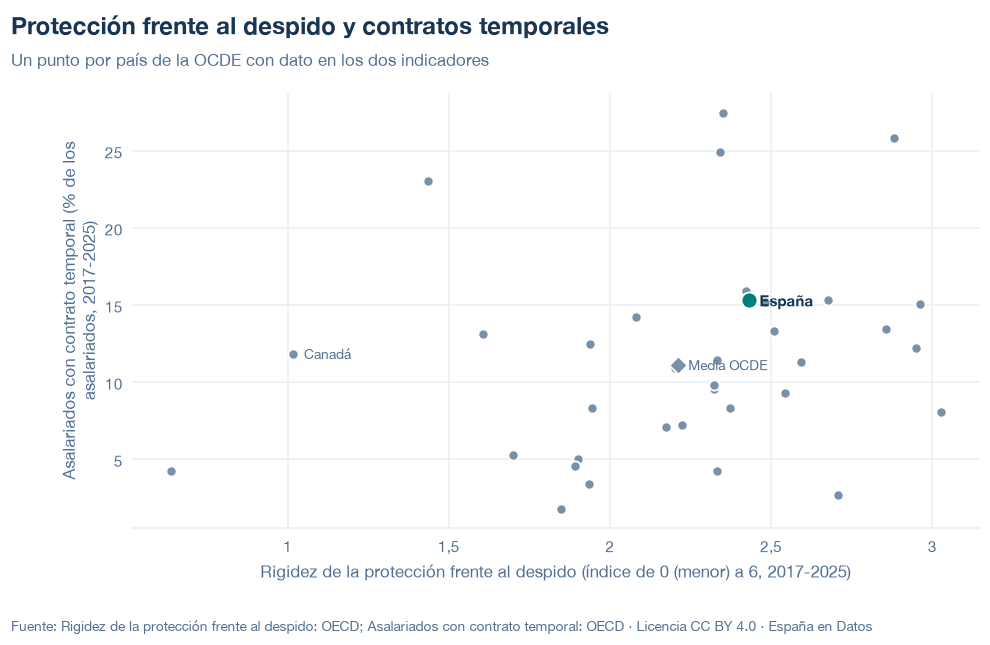

codigo  anio        x      y
   AUS  2017 1.700078  5.268
   AUT  2025 1.943488  8.307
   BEL  2025 2.591117 11.295
   CAN  2025 1.017807 11.844
   CHE  2025 1.606974 13.143
   CHL  2025 2.341766 24.936
   COL  2025 1.435811 23.032
   CRI  2025 0.636905  4.275
   CZE  2025 3.025262  8.101
   DEU  2025 2.332411 11.480
   DNK  2025 1.937693 12.505
   ESP  2025 2.430514 15.307
   EST  2025 1.934223  3.419
   FIN  2025 2.479751 15.210
   FRA  2025 2.675937 15.356
   GBR  2025 1.901724  5.052
   GRC  2025 2.321401  9.576
   HUN  2025 1.892335  4.579
   IRL  2025 2.173195  7.093
   ISL  2024 2.203089 10.910
   ITA  2025 2.855566 13.473
   JPN  2025 2.080915 14.232
   KOR  2025 2.350234 27.484
   LTU  2025 1.848945  1.817
   LUX  2025 2.541837  9.302
   LVA  2025 2.708121  2.669
   NLD  2025 2.880873 25.811
   NOR  2025 2.373485  8.313
   NZL  2025 2.222683  7.205
   POL  2025 2.421032 15.900
   PRT  2025 2.961044 15.062
   SVK  2025 2.330605  4.284
   SVN  2025 2.322110  9.856
   SWE  2025 2

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/proteccion-empleo-temporalidad.json y data/proteccion-empleo-temporalidad.csv


## 6. Fuentes, notas y licencia

- OCDE, indicadores de protección del empleo: `OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0` (`EPL_OV`, `0_TO_6`, `VERSION4`).
- OCDE, empleo según la permanencia del puesto: `OECD.ELS.SAE,DSD_TEMP@DF_TEMP_I,1.0` (`EMP_TEMP`, `PT_POP_SUB`, `_T`, `_T`, `ICSE93_1`, `A`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.